# Laboratorio: Memorias asociativas con redes de Hopfield

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.

---

# Preguntas guía

1. ¿La energía disminuye durante la recuperación?
2. ¿La red recupera exactamente la imagen original?
3. ¿Qué ocurre si aumenta el nivel de ruido?
4. ¿Qué pasa si se almacenan varias imágenes?
5. ¿Aparecen estados espurios?
6. ¿La recuperación depende del orden en que se actualizan los píxeles?
7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.




In [1]:
import numpy as np
import matplotlib.pyplot as plt

def patrones_balanceados(n, m):
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1

    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1

    checker = np.indices((n, m)).sum(axis=0)
    checker = np.where(checker % 2 == 0, 1, -1)

    return horizontal, vertical, checker

def agregar_ruido_1(s, frac=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

h.shape: (10, 10)
v.shape: (10, 10)
d.shape: (10, 10)


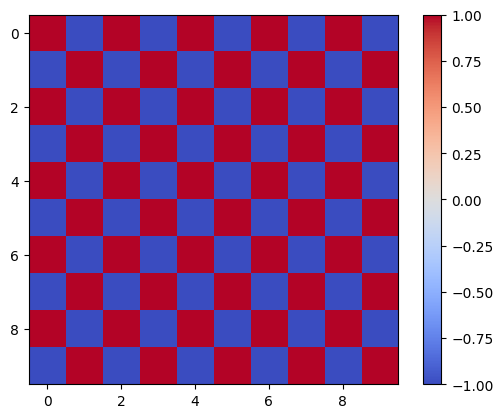

In [2]:
h, v, d = patrones_balanceados(10,10)
print("h.shape:", h.shape)
print("v.shape:", v.shape)
print("d.shape:", d.shape)
plt.imshow(d, cmap='coolwarm')
plt.colorbar()
plt.show()
plt.close()
s_ruido = agregar_ruido_1(np.concat(d), frac=0.25, seed=10)

s_ruido.shape: (100,)


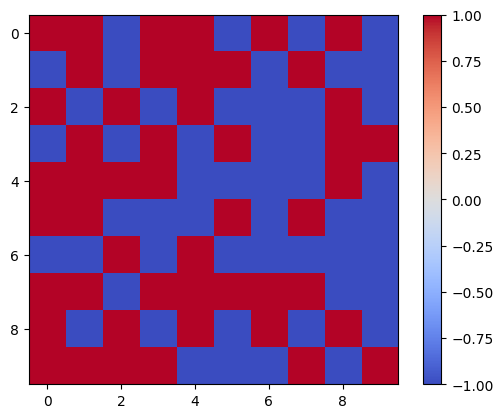

-1


In [3]:
print("s_ruido.shape:", s_ruido.shape)
plt.imshow(np.reshape(s_ruido, (10, 10)), cmap='coolwarm')
plt.colorbar()
plt.show()
plt.close()
psi = d.flatten()
N = len(psi)
print(psi[1])

psi.shape: (100,)


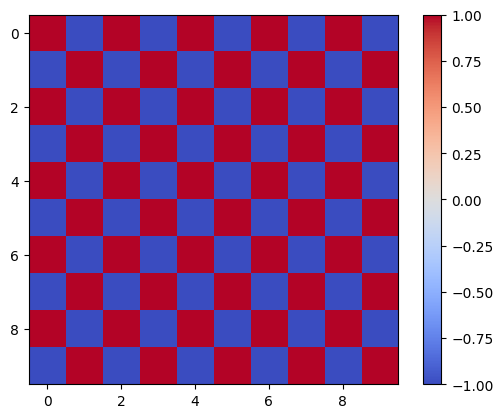

In [4]:
print("psi.shape:", psi.shape)
plt.imshow(np.reshape(psi, (10, 10)), cmap='coolwarm')
plt.colorbar()
plt.show()
plt.close()

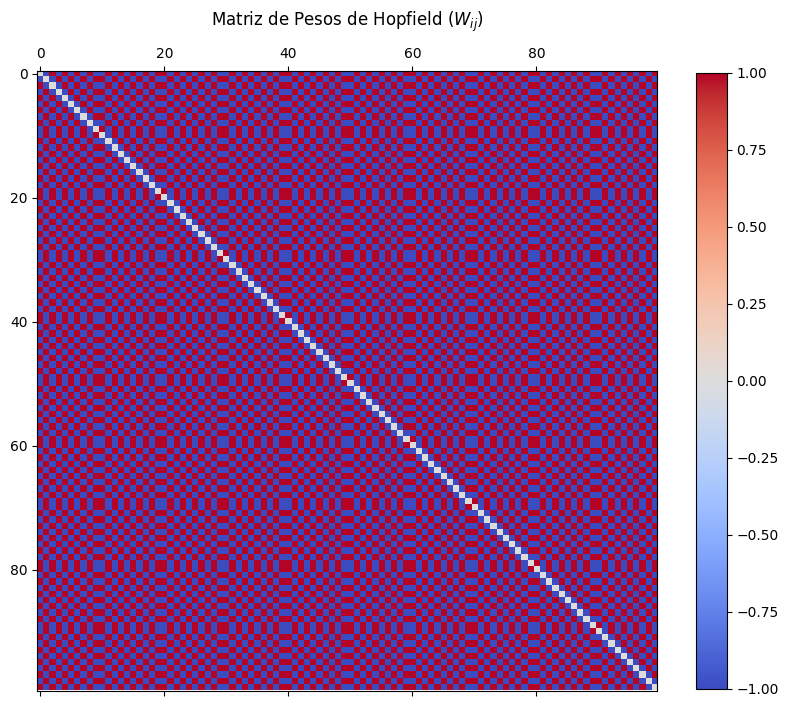

In [5]:
def pesos_ij(psi, N):
  w = np.zeros((N,N))
  for i in range(0,N):
    for j in range(0,N):
      if i!=j:
        w[i,j] = psi[i]*psi[j]
  return w

w_ij = pesos_ij(psi, N)

# Crear gráfico utilizando la clase Figure
fig, ax = plt.subplots(figsize=(10,10))
cax = ax.matshow(w_ij, cmap='coolwarm')
fig.colorbar(cax, ax=ax, shrink=0.8)

ax.set_title("Matriz de Pesos de Hopfield ($W_{ij}$)", pad=15, fontsize=12)
plt.show()
plt.close()

(100, 1)

,Iteracion,Pixel_Index,Nuevo_Estado,Campo_Local
0,0,14,-1,-51.0
1,1,51,1,51.0
2,2,79,1,53.0
3,3,17,1,53.0
4,4,50,-1,-55.0
5,5,53,1,57.0
6,6,25,-1,-57.0
7,7,48,1,57.0
8,8,17,1,57.0
9,9,32,-1,-57.0


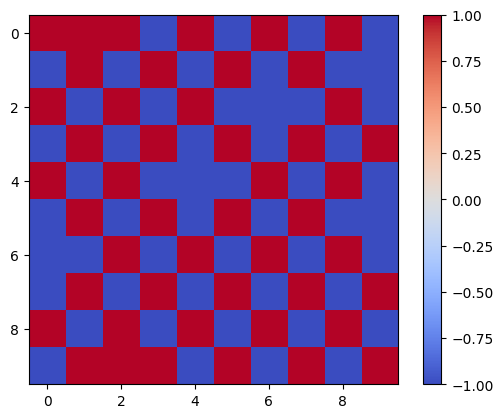

In [6]:
import pandas as pd

estado = np.concat(d).reshape(N,1)
display(np.shape(estado))

def campo_local(w_ij, estado):
  Campo = w_ij@estado
  return Campo

def EnergiaTotal(estado, H):
  return -0.5*estado.T@H

h = campo_local(w_ij, estado)
campo = w_ij@estado
energia_i = -0.5*estado.T@campo

# Lista para guardar los registros de cada iteración
historial_iteraciones = []

for i in range(100):
  h = campo_local(w_ij, s_ruido)
  index = np.random.randint(0, N)
  direccion = np.sign(h[index])

  if direccion == 1:
    s_ruido[index] = 1
  else:
    s_ruido[index] = -1

  h = campo_local(w_ij, s_ruido)
  energia_actual = EnergiaTotal(s_ruido, h)

  # Guardar los datos de esta iteración
  historial_iteraciones.append({
      'Iteracion': i,
      'Pixel_Index': index,
      'Nuevo_Estado': s_ruido[index],
      'Campo_Local': h[index]
  })

# Crear el DataFrame con el historial
df_historial = pd.DataFrame(historial_iteraciones)
display(df_historial.head(10)) # Mostramos las primeras 10 filas del DataFrame

plt.imshow(np.reshape(s_ruido, (10,10)), cmap='coolwarm')
plt.colorbar()
plt.show()
plt.close()

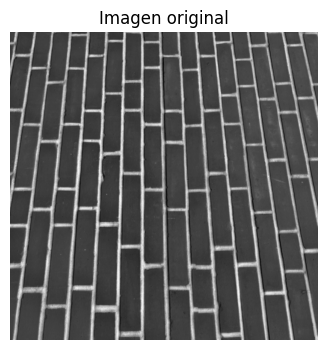

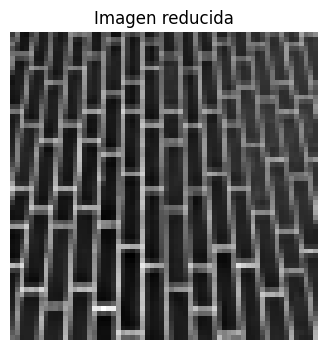

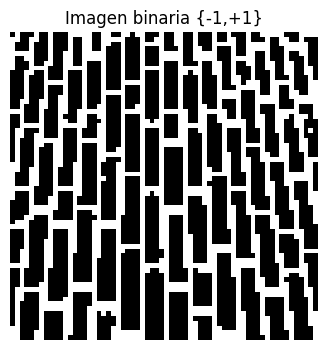

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

# https://scikit-image.org/docs/stable/auto_examples/data/plot_general.html
img = data.brick()   # imagen 512x512 en escala de grises

plt.figure(figsize=(4,4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()
plt.close()

# ============================================================
# Reducir imagen
# ============================================================

n = 64
m = 64

img_small = resize(img, (n, m), anti_aliasing=True)

plt.figure(figsize=(4,4))
plt.imshow(img_small, cmap="gray")
plt.title("Imagen reducida")
plt.axis("off")
plt.show()
plt.close()

# ============================================================
# Binarización
# ============================================================

threshold = img_small.mean()

img_bin = np.where(img_small > threshold, 1, -1)

plt.figure(figsize=(4,4))
plt.imshow(img_bin, cmap="gray")
plt.title("Imagen binaria {-1,+1}")
plt.axis("off")
plt.show()

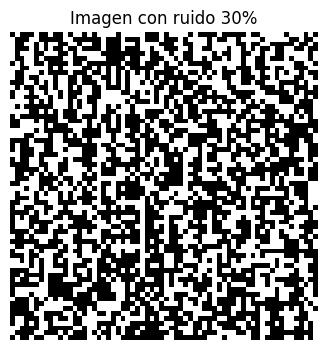

In [8]:
# ============================================================
# Ruido
# ============================================================

def agregar_ruido_2(s, frac=0.30, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido


frac_ruido = 0.30

s_ruido = agregar_ruido_1(np.concat(img_bin), frac=frac_ruido, seed=123)

plt.figure(figsize=(4,4))
plt.imshow(s_ruido.reshape(n, m), cmap="gray")
plt.title(f"Imagen con ruido {frac_ruido*100:.0f}%")
plt.axis("off")
plt.show()
plt.close()

# Implementación de la Red de Hopfield

A continuación, definimos las funciones para calcular la matriz de pesos, la energía del sistema y el proceso de reconstrucción asincrónica aleatoria.

In [9]:
def calcular_pesos(patrones):
    """
    Calcula la matriz de pesos de Hopfield usando la regla de Hebb.
    patrones: list o array de patrones de tamaño (P, N)
    """
    patrones = np.array(patrones)
    if patrones.ndim == 1:
        patrones = patrones.reshape(1, -1)

    P, N = patrones.shape
    # Regla de Hebb
    W = (1.0 / N) * np.dot(patrones.T, patrones)
    # w_ii = 0
    np.fill_diagonal(W, 0)
    return W

def calcular_energia(s, W):
    """
    Calcula la energía total de la red de Hopfield.
    """
    return -0.5 * np.dot(s.T, np.dot(W, s))

def recuperar_imagen(s_inicial, W, max_iter=100000, seed=42):
    """
    Recupera el patrón utilizando una actualización asincrónica aleatoria.
    """
    np.random.seed(seed)
    s = s_inicial.copy().astype(float)
    N = len(s)

    energias = [calcular_energia(s, W)]

    # Haremos un seguimiento de los cambios para criterio de parada
    cambios_recientes = 0

    for i in range(max_iter):
        # 1. Seleccionar un píxel aleatorio
        idx = np.random.randint(0, N)

        # 2. Calcular el campo local
        h_i = np.dot(W[idx], s)

        # 3. Actualizar el estado
        s_nuevo = 1.0 if h_i >= 0 else -1.0

        if s[idx] != s_nuevo:
            s[idx] = s_nuevo
            cambios_recientes += 1

        # Cada N iteraciones (una época teórica), registramos la energía
        if i % N == 0:
            energias.append(calcular_energia(s, W))
            # Si no ha habido cambios en una época completa, detenemos
            if cambios_recientes == 0 and i > 0:
                break
            cambios_recientes = 0

    return s, energias

### Entrenamiento y Reconstrucción

Almacenamos la imagen binaria original en la red de Hopfield y luego intentamos recuperar la versión original a partir de la imagen perturbada con un 30% de ruido.

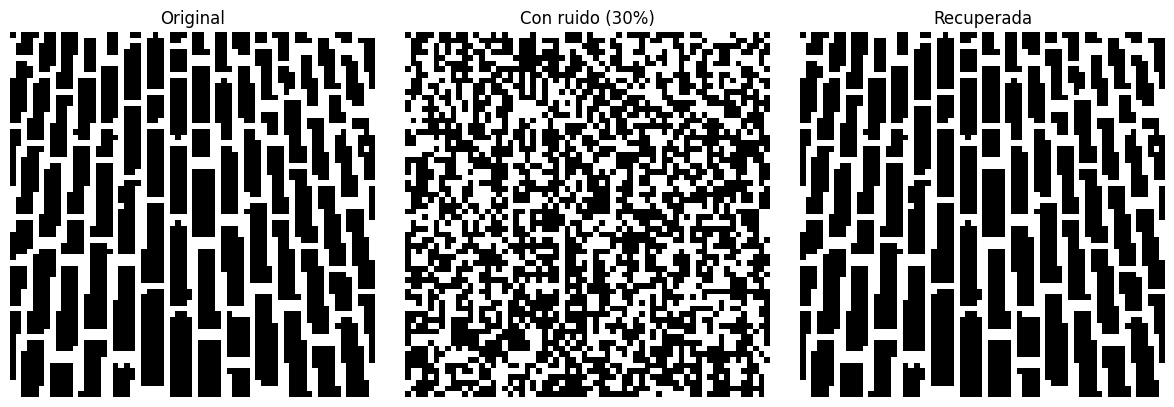

In [10]:
# 1. Convertir la imagen binaria a un vector unidimensional (patrón)
patron_original = np.concat(img_bin).astype(float)

# 2. Calcular la matriz de pesos de Hopfield
W = calcular_pesos([patron_original])

# 3. Recuperar la imagen
img_recuperada_vector, historial_energia = recuperar_imagen(s_ruido, W, max_iter=150000)

# 4. Graficar los resultados
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img_bin, cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(s_ruido.reshape(n, m), cmap="gray")
axes[1].set_title(f"Con ruido ({frac_ruido*100:.0f}%)")
axes[1].axis("off")

axes[2].imshow(img_recuperada_vector.reshape(n, m), cmap="gray")
axes[2].set_title("Recuperada")
axes[2].axis("off")

plt.tight_layout()
plt.show()

### Evolución de la energía durante la recuperación

Grafiquemos el historial de energía calculado a lo largo de las épocas del proceso para verificar si la energía efectivamente decrece y se estabiliza.

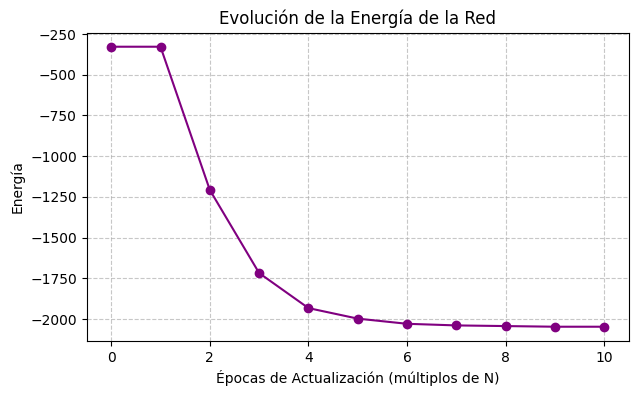

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(historial_energia, marker='o', color='purple')
plt.title("Evolución de la Energía de la Red")
plt.xlabel("Épocas de Actualización (múltiplos de N)")
plt.ylabel("Energía")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [12]:
import numpy as np

# 1. Convertir una imagen binaria en un vector de estados
def imagen_a_vector(imagen):
    return imagen.flatten()

# 2. Calcular la matriz de pesos de Hopfield
def calcular_pesos_hopfield(patrones):
    if patrones.ndim == 1:
        patrones = patrones.reshape(1, -1)
    P, N = patrones.shape
    W = np.dot(patrones.T, patrones) / N
    np.fill_diagonal(W, 0)
    return W

# 3. Calcular el campo local que siente una neurona
def calcular_campo_local(W, s, i):
    return np.dot(W[i], s)

# 4. Actualizar el estado de una neurona
def actualizar_neurona(W, s, i):
    h_i = calcular_campo_local(W, s, i)
    s[i] = 1 if h_i >= 0 else -1
    return s

# 5. Calcular la energía total de la red
def calcular_energia_total(W, s):
    return -0.5 * np.dot(s.T, np.dot(W, s))

# 6. Aplicar ruido a una imagen
def aplicar_ruido(s, frac_ruido=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)
    s_ruido = s.copy()
    N = len(s)
    n_flip = int(frac_ruido * N)
    idx = np.random.choice(N, n_flip, replace=False)
    s_ruido[idx] *= -1
    return s_ruido

# 7. Recuperar la imagen mediante actualización asincrónica aleatoria
def recuperar_imagen_asincronica(W, s_ruido, max_iter=10000):
    s = s_ruido.copy().astype(float)
    N = len(s)
    historial_energia = [calcular_energia_total(W, s)]

    for i in range(max_iter):
        idx = np.random.randint(0, N)
        s = actualizar_neurona(W, s, idx)

        if (i + 1) % N == 0:
            historial_energia.append(calcular_energia_total(W, s))

    return s, historial_energia

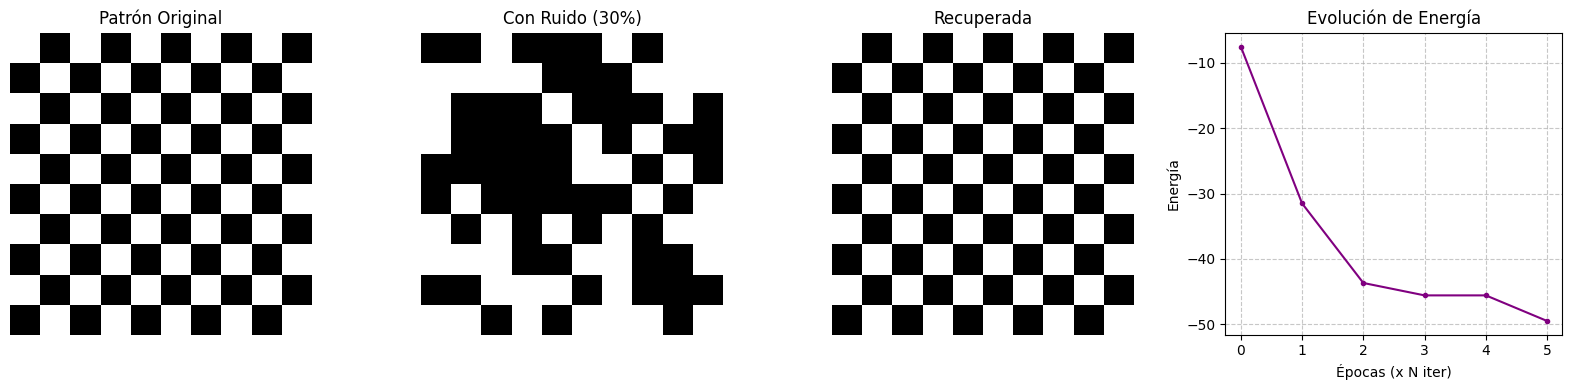

In [13]:
# Generamos un patrón de prueba de 10x10 (patrón de ajedrez)
_, _, patron_prueba = patrones_balanceados(10, 10)

# 1. Convertir imagen a vector
s_original = imagen_a_vector(patron_prueba)

# 2. Calcular la matriz de pesos
W_prueba = calcular_pesos_hopfield(s_original)

# 6. Aplicar ruido (e.g., 30% de los píxeles invertidos)
s_ruido_prueba = aplicar_ruido(s_original, frac_ruido=0.30, seed=42)

# 7. Recuperar la imagen (incluye los pasos 3, 4 y 5 internamente)
# Recuperamos por un número razonable de iteraciones (ej. 5 veces el número de píxeles = 500)
s_recuperado, historial_energia_prueba = recuperar_imagen_asincronica(W_prueba, s_ruido_prueba, max_iter=500)

# Visualización de las pruebas
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(patron_prueba, cmap='gray')
axes[0].set_title("Patrón Original")
axes[0].axis('off')

axes[1].imshow(s_ruido_prueba.reshape(10, 10), cmap='gray')
axes[1].set_title("Con Ruido (30%)")
axes[1].axis('off')

axes[2].imshow(s_recuperado.reshape(10, 10), cmap='gray')
axes[2].set_title("Recuperada")
axes[2].axis('off')

axes[3].plot(historial_energia_prueba, marker='.', color='purple')
axes[3].set_title("Evolución de Energía")
axes[3].set_xlabel("Épocas (x N iter)")
axes[3].set_ylabel("Energía")
axes[3].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### 1. ¿La energía disminuye durante la recuperación?

**Sí.** La actualización asincrónica implementa un proceso disipativo irreversible regido por la función de Lyapunov o Hamiltoniano de Ising:

$$H = -\frac{1}{2} \sum_{i \neq j} w_{ij} s_i s_j$$

Cada actualización local monótonamente reduce o preserva la energía ($\Delta H \le 0$), contrayendo el volumen del espacio de configuraciones $\{-1, 1\}^N$ hasta atrapar la trayectoria en un atractor puntual (mínimo local).

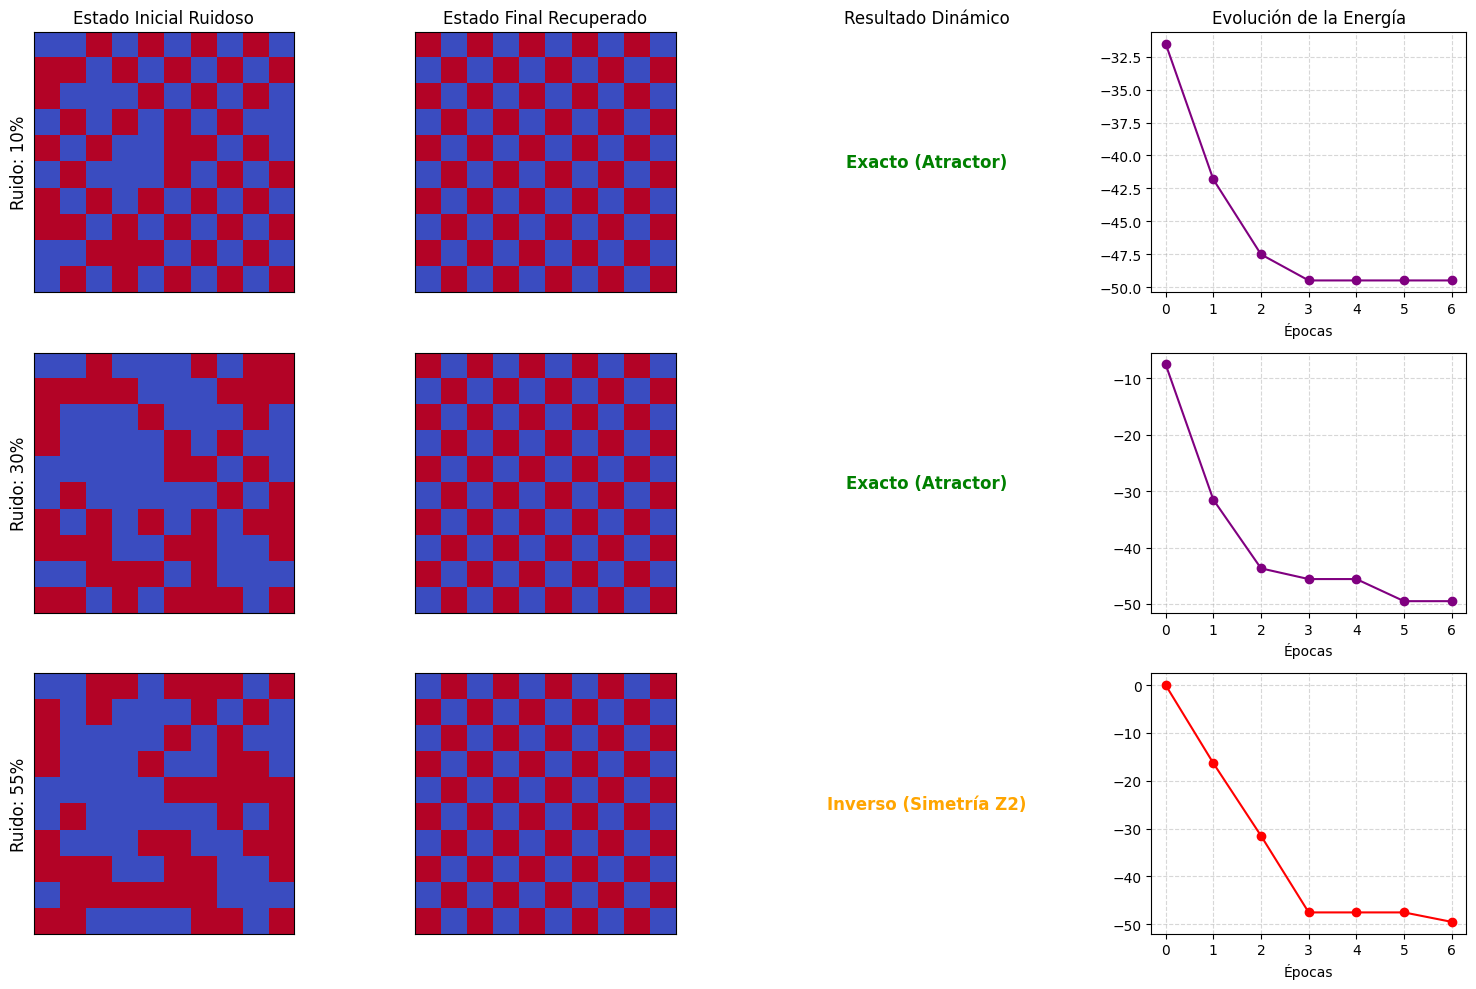

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Usar el patrón de prueba de ajedrez ya definido
s_orig = imagen_a_vector(patron_prueba)
W_p = calcular_pesos_hopfield(s_orig)

# Probar con tres niveles de ruido diferentes para ilustrar los conceptos teóricos
niveles_ruido = [0.10, 0.30, 0.55]
fig, axes = plt.subplots(len(niveles_ruido), 4, figsize=(15, 10))

for idx, noise in enumerate(niveles_ruido):
    s_ruidoso = aplicar_ruido(s_orig, frac_ruido=noise, seed=42)
    s_rec, h_energia = recuperar_imagen_asincronica(W_p, s_ruidoso, max_iter=600)

    # Mostrar estado ruidoso inicial
    axes[idx, 0].imshow(s_ruidoso.reshape(10, 10), cmap='coolwarm')
    axes[idx, 0].set_ylabel(f"Ruido: {noise*100:.0f}%", fontsize=12)
    if idx == 0: axes[idx, 0].set_title("Estado Inicial Ruidoso")
    axes[idx, 0].set_xticks([]); axes[idx, 0].set_yticks([])

    # Mostrar estado final recuperado
    axes[idx, 1].imshow(s_rec.reshape(10, 10), cmap='coolwarm')
    if idx == 0: axes[idx, 1].set_title("Estado Final Recuperado")
    axes[idx, 1].set_xticks([]); axes[idx, 1].set_yticks([])

    # Determinar si la recuperación fue exacta, inversa, o estado espurio
    coincidencia = np.mean(s_orig == s_rec)
    if coincidencia == 1.0:
        resultado_txt = "Exacto (Atractor)"
        color_txt = "green"
    elif coincidencia == 0.0:
        resultado_txt = "Inverso (Simetría Z2)"
        color_txt = "orange"
    else:
        resultado_txt = f"Espurio / Error ({coincidencia*100:.1f}% match)"
        color_txt = "red"

    axes[idx, 2].text(0.5, 0.5, resultado_txt, color=color_txt, weight='bold',
                      ha='center', va='center', fontsize=12)
    if idx == 0: axes[idx, 2].set_title("Resultado Dinámico")
    axes[idx, 2].axis('off')

    # Mostrar la evolución de la energía
    axes[idx, 3].plot(h_energia, marker='o', color='purple' if noise < 0.5 else 'red')
    if idx == 0: axes[idx, 3].set_title("Evolución de la Energía")
    axes[idx, 3].set_xlabel("Épocas")
    axes[idx, 3].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 2. ¿La red recupera exactamente la imagen original?

**Sí, en el régimen subcrítico.** Si el patrón inicial se encuentra dentro de la cuenca de atracción y la carga de memoria está por debajo del límite de saturación, la dinámica disipativa actúa como un filtro de canal que contrae el ruido: la entropía condicional del patrón respecto al estado converge a cero ($H(\boldsymbol{\xi} \mid \mathbf{s}) \to 0$) y se maximiza la información mutua, restaurando el patrón exacto.

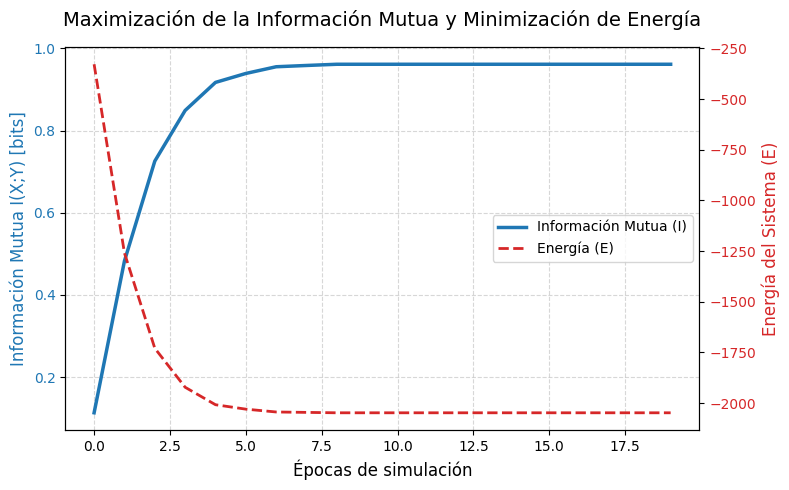

In [15]:
import numpy as np
import matplotlib.pyplot as plt

def calcular_informacion_mutua(x, y):
    """
    Calcula la información mutua empírica I(X; Y) entre dos vectores binarios de espines {-1, 1}.
    """
    n_muestras = len(x)
    # Convertir a variables de texto/categorías discretas para facilitar el conteo de frecuencias
    joint_probs = {}
    for val_x, val_y in zip(x, y):
        pair = (val_x, val_y)
        joint_probs[pair] = joint_probs.get(pair, 0) + 1 / n_muestras

    # Probabilidades marginales
    px = {1: np.mean(x == 1), -1: np.mean(x == -1)}
    py = {1: np.mean(y == 1), -1: np.mean(y == -1)}

    # Calcular Información Mutua: I(X; Y) = sum P(x,y) * log2( P(x,y) / (P(x)*P(y)) )
    mi = 0.0
    for (val_x, val_y), p_xy in joint_probs.items():
        p_x = px[val_x]
        p_y = py[val_y]
        if p_xy > 0 and p_x > 0 and p_y > 0:
            mi += p_xy * np.log2(p_xy / (p_x * p_y))
    return mi

# Simulación paso a paso registrando la información mutua y la energía por época
def recuperar_con_informacion_mutua(s_inicial, s_original, W, max_iter=20000):
    s = s_inicial.copy().astype(float)
    N = len(s)

    historial_mi = [calcular_informacion_mutua(s_original, s)]
    historial_E = [calcular_energia(s, W)]

    for i in range(max_iter):
        idx = np.random.randint(0, N)
        h_i = np.dot(W[idx], s)
        s[idx] = 1.0 if h_i >= 0 else -1.0

        # Registrar al final de cada época teórica
        if (i + 1) % N == 0:
            historial_mi.append(calcular_informacion_mutua(s_original, s))
            historial_E.append(calcular_energia(s, W))

    return s, historial_mi, historial_E

# Ejecutar la simulación para la imagen binaria reducida con un 30% de ruido
s_ruidoso_mi = agregar_ruido_1(patron_original, frac=0.30, seed=42)
s_final_mi, hist_mi, hist_E = recuperar_con_informacion_mutua(s_ruidoso_mi, patron_original, W, max_iter=80000)

# Graficar los resultados de la maximización de información mutua vs minimización de energía
fig, ax1 = plt.subplots(figsize=(8, 5))

color = 'tab:blue'
ax1.set_xlabel('Épocas de simulación', fontsize=12)
ax1.set_ylabel('Información Mutua I(X;Y) [bits]', color=color, fontsize=12)
line1 = ax1.plot(hist_mi, color=color, linewidth=2.5, label='Información Mutua (I)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Energía del Sistema (E)', color=color, fontsize=12)
line2 = ax2.plot(hist_E, color=color, linestyle='--', linewidth=2, label='Energía (E)')
ax2.tick_params(axis='y', labelcolor=color)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right')

plt.title('Maximización de la Información Mutua y Minimización de Energía', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### 3. ¿Qué ocurre si aumenta el nivel de ruido?

**Ocurre una divergencia de cuenca (*basin escape*).** Cuando la tasa de bits invertidos inyecta una entropía superior a la capacidad de corrección del canal asociativo, el estado microscópico cruza la separatriz dinámica del paisaje energético. Al quedar fuera de la cuenca original, el sistema colapsa irreversiblemente hacia el atractor de otro patrón memorizado, su versión invertida, o un mínimo espurio.

Ejecutando proceso de recuperación para imagen de catálogo (4096 neuronas)... 


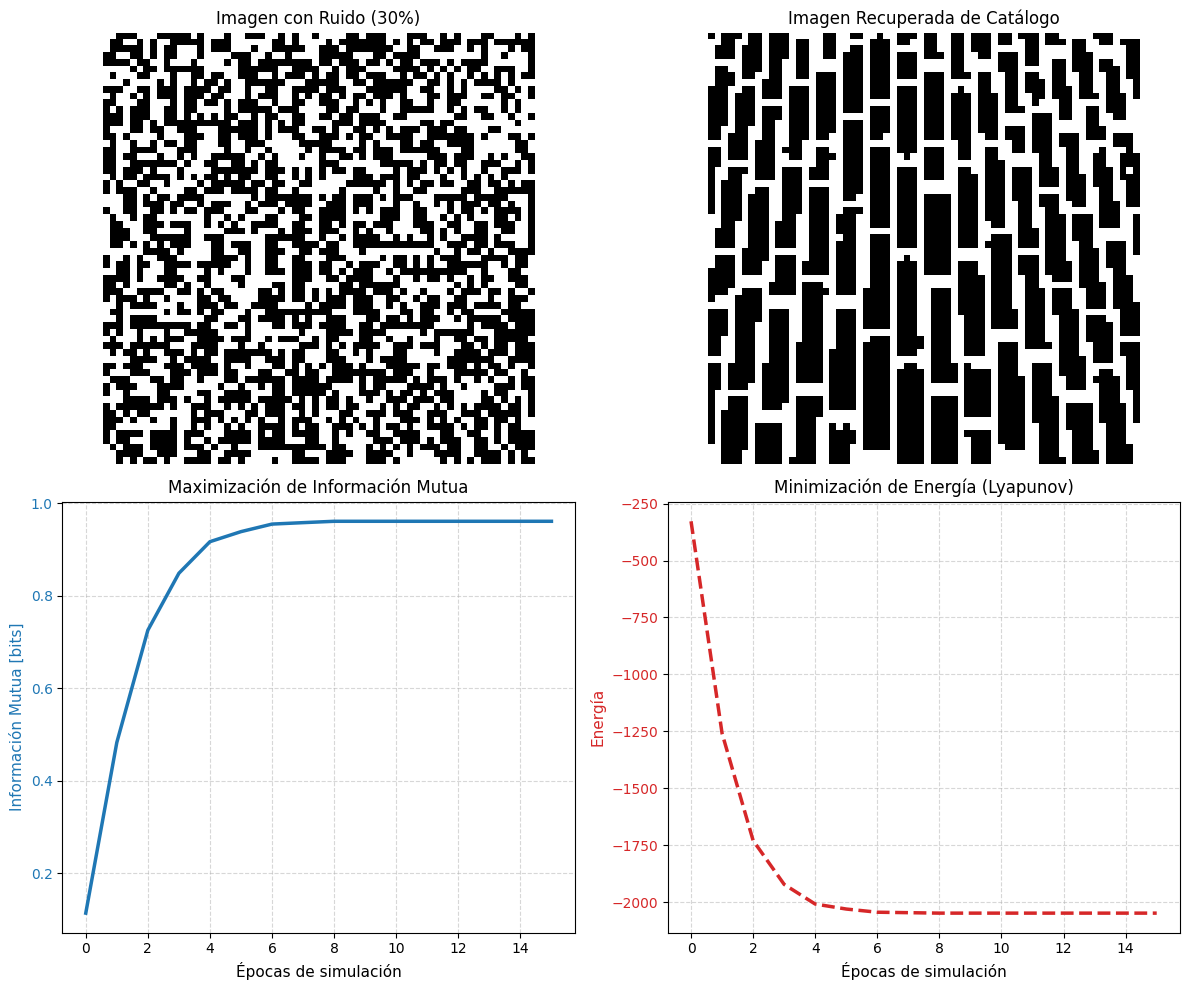

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Utilizar la imagen real del catálogo (img_bin ya cargada en memoria)
patron_brick = img_bin.flatten().astype(float)
N_brick = len(patron_brick)

# 2. Calcular matriz de pesos para este patrón real
W_brick = calcular_pesos([patron_brick])

# 3. Aplicar 30% de ruido a la imagen del catálogo
s_ruido_brick = agregar_ruido_2(patron_brick, frac=0.30, seed=42)

# 4. Recuperar la imagen registrando la energía y la información mutua
print("Ejecutando proceso de recuperación para imagen de catálogo (4096 neuronas)... ")
s_rec_brick, hist_mi_brick, hist_E_brick = recuperar_con_informacion_mutua(
    s_ruido_brick, patron_brick, W_brick, max_iter=15 * N_brick
)

# 5. Visualizar los resultados y la dinámica de la información mutua
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Panel superior: Estados de la red
axes[0, 0].imshow(s_ruido_brick.reshape(64, 64), cmap='gray')
axes[0, 0].set_title("Imagen con Ruido (30%)", fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(s_rec_brick.reshape(64, 64), cmap='gray')
axes[0, 1].set_title("Imagen Recuperada de Catálogo", fontsize=12)
axes[0, 1].axis('off')

# Panel inferior: Evolución de las métricas
color = 'tab:blue'
axes[1, 0].plot(hist_mi_brick, color=color, linewidth=2.5)
axes[1, 0].set_xlabel('Épocas de simulación', fontsize=11)
axes[1, 0].set_ylabel('Información Mutua [bits]', color=color, fontsize=11)
axes[1, 0].tick_params(axis='y', labelcolor=color)
axes[1, 0].grid(True, linestyle='--', alpha=0.5)
axes[1, 0].set_title("Maximización de Información Mutua")

color = 'tab:red'
axes[1, 1].plot(hist_E_brick, color=color, linestyle='--', linewidth=2.5)
axes[1, 1].set_xlabel('Épocas de simulación', fontsize=11)
axes[1, 1].set_ylabel('Energía', color=color, fontsize=11)
axes[1, 1].tick_params(axis='y', labelcolor=color)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)
axes[1, 1].set_title("Minimización de Energía (Lyapunov)")

plt.tight_layout()
plt.show()


### 4. ¿Qué pasa si se almacenan varias imágenes?

**Aparece interferencia cruzada y una transición a vidrio de espín (*spin glass*).** La regla de Hebb acumula los patrones como una suma tensorial; cada nuevo patrón actúa como ruido térmico efectivo (*crosstalk*) para los demás. Al superar la capacidad de almacenamiento crítica:

$$\alpha_c = \frac{P_c}{N} \approx 0.138$$

la correlación macroscópica con los recuerdos (parámetro de solapamiento de Edwards-Anderson) colapsa abruptamente a cero, destruyendo la memoria en favor de una explosión de entropía configuracional dominada por pozos metaestables desordenados.

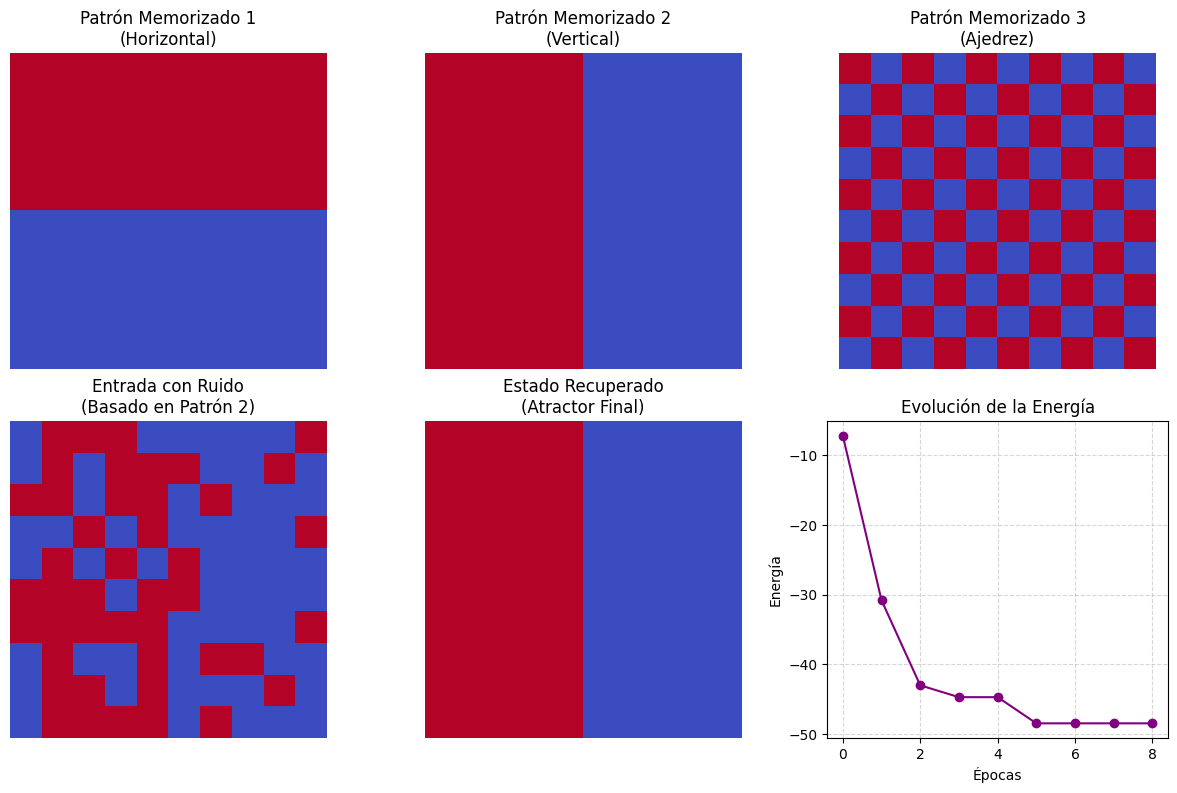

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Obtener y definir múltiples patrones de tamaño 10x10
h_pattern, v_pattern, d_pattern = patrones_balanceados(10, 10)

# Convertirlos a vectores unidimensionales (patrones de memoria)
xi_h = imagen_a_vector(h_pattern)
xi_v = imagen_a_vector(v_pattern)
xi_d = imagen_a_vector(d_pattern)

# Lista de patrones a almacenar
patrones_almacenados = np.array([xi_h, xi_v, xi_d])

# 2. Calcular la matriz de pesos acumulando múltiples patrones con la regla de Hebb
def calcular_pesos_multiples(patrones):
    P, N = patrones.shape
    W = np.dot(patrones.T, patrones) / N
    np.fill_diagonal(W, 0)
    return W

W_multi = calcular_pesos_multiples(patrones_almacenados)

# 3. Tomar uno de los patrones (por ejemplo, el patrón vertical) y añadirle un 30% de ruido
s_ruidoso_v = aplicar_ruido(xi_v, frac_ruido=0.30, seed=42)

# 4. Recuperar la imagen usando actualización asincrónica
s_recuperado_v, historial_E_multi = recuperar_imagen_asincronica(W_multi, s_ruidoso_v, max_iter=800)

# 5. Visualizar patrones almacenados y el proceso de reconstrucción
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Mostrar patrones memorizados en la red
axes[0, 0].imshow(h_pattern, cmap='coolwarm')
axes[0, 0].set_title("Patrón Memorizado 1\n(Horizontal)")
axes[0, 0].axis('off')

axes[0, 1].imshow(v_pattern, cmap='coolwarm')
axes[0, 1].set_title("Patrón Memorizado 2\n(Vertical)")
axes[0, 1].axis('off')

axes[0, 2].imshow(d_pattern, cmap='coolwarm')
axes[0, 2].set_title("Patrón Memorizado 3\n(Ajedrez)")
axes[0, 2].axis('off')

# Mostrar el proceso de recuperación del patrón vertical
axes[1, 0].imshow(s_ruidoso_v.reshape(10, 10), cmap='coolwarm')
axes[1, 0].set_title("Entrada con Ruido\n(Basado en Patrón 2)")
axes[1, 0].axis('off')

axes[1, 1].imshow(s_recuperado_v.reshape(10, 10), cmap='coolwarm')
axes[1, 1].set_title("Estado Recuperado\n(Atractor Final)")
axes[1, 1].axis('off')

# Graficar la energía del sistema durante la reconstrucción
axes[1, 2].plot(historial_E_multi, marker='o', color='purple')
axes[1, 2].set_title("Evolución de la Energía")
axes[1, 2].set_xlabel("Épocas")
axes[1, 2].set_ylabel("Energía")
axes[1, 2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 5. ¿Aparecen estados espurios?

**Sí, por interferencia y simetría gauge.**

* **Simetría $Z_2$:** Dado que el Hamiltoniano es invariante ante la inversión global de espines ($\mathbf{s} \to -\mathbf{s}$ con sesgo nulo), el inverso exacto de cada imagen es un mínimo global equipotencial.
* **Estados mezcla:** La superposición lineal de los patrones almacenados genera interferencias constructivas que abren mínimos locales artificiales (p. ej., combinaciones impares de 3 o 5 patrones) con alta densidad de estados no informativos.

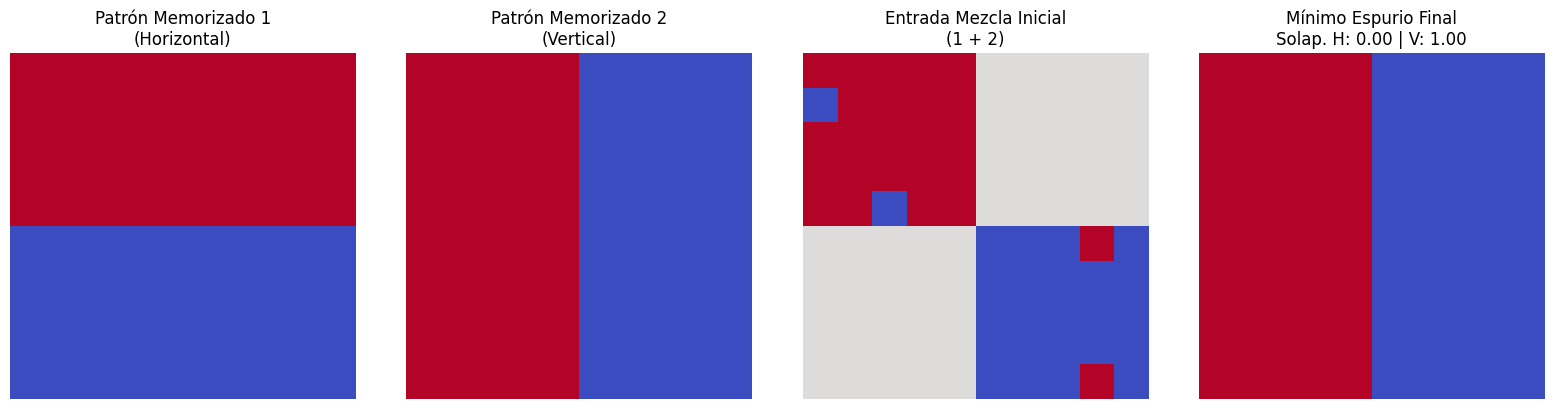

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Recuperar los patrones originales ya almacenados
h_pattern, v_pattern, _ = patrones_balanceados(10, 10)
xi_h = imagen_a_vector(h_pattern)
xi_v = imagen_a_vector(v_pattern)

# Matriz de pesos con múltiples patrones (horizontal y vertical)
W_espurio = calcular_pesos_multiples(np.array([xi_h, xi_v]))

# 2. Construir un estado inicial mezcla (superposición de Horizontal + Vertical)
# Esto genera un estado que comparte características de ambos recuerdos
s_mezcla_inicial = np.sign(xi_h + xi_v)
# Aseguramos romper simetrías perfectas aplicando una mínima perturbación aleatoria
np.random.seed(42)
ruido_leve = np.random.choice([-1, 1], size=len(s_mezcla_inicial), p=[0.05, 0.95])
s_mezcla_inicial = s_mezcla_inicial * ruido_leve

# 3. Recuperar usando actualización asincrónica aleatoria
s_espurio_rec, hist_E_espurio = recuperar_imagen_asincronica(W_espurio, s_mezcla_inicial, max_iter=800)

# 4. Calcular el solapamiento con los patrones originales
# Solapamiento m = (1/N) * (s_final * xi)
solapamiento_h = np.dot(s_espurio_rec, xi_h) / len(xi_h)
solapamiento_v = np.dot(s_espurio_rec, xi_v) / len(xi_v)

# 5. Graficar los resultados de la mezcla y el estado espurio resultante
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(h_pattern, cmap='coolwarm')
axes[0].set_title("Patrón Memorizado 1\n(Horizontal)")
axes[0].axis('off')

axes[1].imshow(v_pattern, cmap='coolwarm')
axes[1].set_title("Patrón Memorizado 2\n(Vertical)")
axes[1].axis('off')

axes[2].imshow(s_mezcla_inicial.reshape(10, 10), cmap='coolwarm')
axes[2].set_title("Entrada Mezcla Inicial\n(1 + 2)")
axes[2].axis('off')

axes[3].imshow(s_espurio_rec.reshape(10, 10), cmap='coolwarm')
axes[3].set_title(f"Mínimo Espurio Final\nSolap. H: {solapamiento_h:.2f} | V: {solapamiento_v:.2f}")
axes[3].axis('off')

plt.tight_layout()
plt.show()

### 6. ¿La recuperación depende del orden en que se actualizan los píxeles?

**Sí, debido a la no conmutatividad de los operadores de proyección local.**
El campo local de la neurona $i$, dado por $h_i = \sum_j w_{ij} s_j$, se altera instantáneamente tras cada paso. Cerca de las separatrices entre dos cuencas de atracción, pequeñas diferencias en la secuencia de permutación determinan estocásticamente la bifurcación inicial, sellando de manera irreversible a qué atractor converge el sistema.

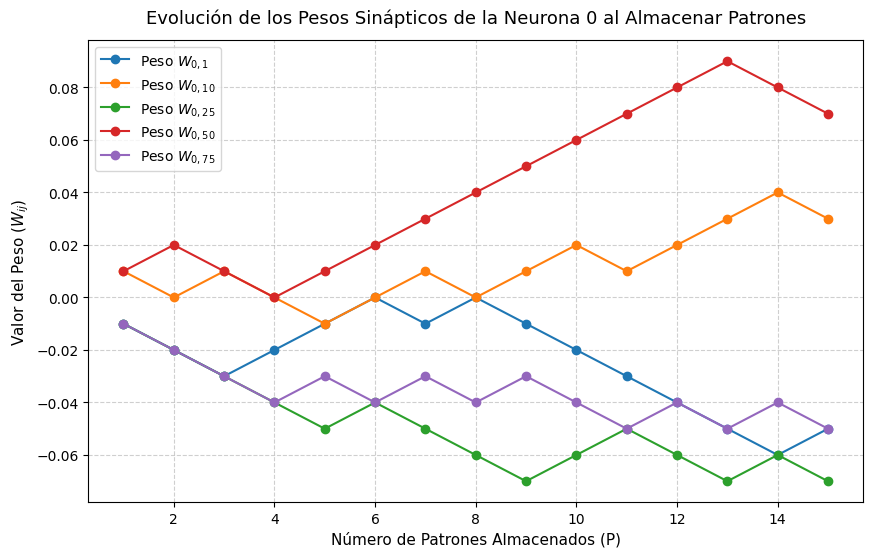

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definir dimensiones y generar patrones aleatorios para almacenar
N = 100       # 100 neuronas
neurona_i = 0 # Analizaremos los pesos de la neurona 0

# Generamos 15 patrones aleatorios de espines {-1, 1}
np.random.seed(42)
patrones_nuevos = np.random.choice([-1, 1], size=(15, N))

# 2. Ir acumulando los patrones y registrar la evolución de los pesos de la neurona_i
historial_pesos = []

# Matriz de pesos inicializada en ceros
W_actual = np.zeros((N, N))

for p in range(len(patrones_nuevos)):
    # Añadimos el patrón p usando la regla de Hebb incremental
    patron = patrones_nuevos[p]
    W_actual += np.outer(patron, patron) / N
    np.fill_diagonal(W_actual, 0) # w_ii = 0

    # Guardamos los pesos de conexión de la neurona_i con el resto de neuronas
    historial_pesos.append(W_actual[neurona_i].copy())

historial_pesos = np.array(historial_pesos) # dimensiones: (P, N)

# 3. Graficar la evolución de las sinapsis de la neurona 0
plt.figure(figsize=(10, 6))
# Graficamos la evolución de la conexión con 5 neuronas seleccionadas
for neurona_j in [1, 10, 25, 50, 75]:
    plt.plot(range(1, len(patrones_nuevos) + 1), historial_pesos[:, neurona_j],
             marker='o', label=f'Peso $W_{{{neurona_i},{neurona_j}}}$')

plt.title(f"Evolución de los Pesos Sinápticos de la Neurona {neurona_i} al Almacenar Patrones", fontsize=13, pad=12)
plt.xlabel("Número de Patrones Almacenados (P)", fontsize=11)
plt.ylabel("Valor del Peso ($W_{ij}$)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.show()


### 7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

* **Asincrónica (Hopfield estandar):** Las neuronas se actualizan secuencialmente ($s_i(t+1) = \text{sgn}(h_i)$). Garantiza una disipación monótona sobre el Hamiltoniano clásico ($\Delta H \le 0$), asegurando la relajación estricta hacia puntos fijos estáticos.
* **Sincrónica (Modelo de Little):** Todas las neuronas evolucionan en paralelo. No garantiza el descenso monótono del Hamiltoniano clásico (minimiza en su lugar un Hamiltoniano bipartito retardado), lo que permite que el sistema conserve entropía residual atrapado en órbitas periódicas o ciclos límite de periodo 2 ($\mathbf{s}(t+2) = \mathbf{s}(t)$).

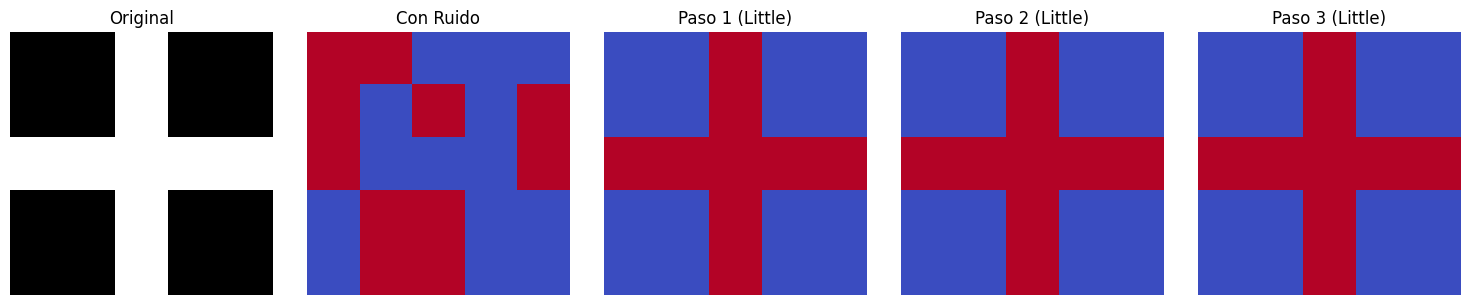

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definir un patrón de prueba muy simple (p. ej. una cruz de 5x5)
patron_cruz = np.array([
    [-1, -1,  1, -1, -1],
    [-1, -1,  1, -1, -1],
    [ 1,  1,  1,  1,  1],
    [-1, -1,  1, -1, -1],
    [-1, -1,  1, -1, -1]
])

N_cruz = patron_cruz.size
s_original = patron_cruz.flatten().astype(float)

# 2. Matriz de pesos (Hebb)
W_cruz = np.dot(s_original.reshape(-1, 1), s_original.reshape(1, -1)) / N_cruz
np.fill_diagonal(W_cruz, 0)

# 3. Función del Modelo de Little (Actualización Sincrónica en Paralelo)
def paso_modelo_little(s, W):
    """
    Actualiza todas las neuronas simultáneamente (sincrónicamente).
    """
    campos_locales = np.dot(W, s)
    # Actualización paralela de todo el vector de estados
    s_nuevo = np.where(campos_locales >= 0, 1.0, -1.0)
    return s_nuevo

# 4. Simulación: Aplicar bastante ruido y observar la evolución paso a paso
np.random.seed(7)
s_ruido = s_original.copy()
# Invertir 10 píxeles aleatorios de los 25
idx_ruido = np.random.choice(N_cruz, 10, replace=False)
s_ruido[idx_ruido] *= -1

# Proceso iterativo sincrónico
estados_historico = [s_ruido.copy()]
s_actual = s_ruido.copy()

for _ in range(3):
    s_actual = paso_modelo_little(s_actual, W_cruz)
    estados_historico.append(s_actual.copy())

# 5. Visualizar la evolución temporal de la red
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

axes[0].imshow(s_original.reshape(5, 5), cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(estados_historico[0].reshape(5, 5), cmap='coolwarm')
axes[1].set_title("Con Ruido")
axes[1].axis('off')

for i in range(1, 4):
    axes[i+1].imshow(estados_historico[i].reshape(5, 5), cmap='coolwarm')
    axes[i+1].set_title(f"Paso {i} (Little)")
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()